# Miami smelter • acquired-history review

**2016-01-01 through 2026-10-18 • two-pixel main candidate + seven-pixel context**

Select EI-Nightlights (.venv), then Run All. Saved outputs are included. All science processing uses existing local data; the raw archives remain intact. The original 2016 review follows the full-history results.

In [1]:
import sys
import importlib.util
from pathlib import Path
import json
print('Python:', sys.executable)
missing = [m for m in ['rioxarray','xarray','pandas','numpy','matplotlib'] if importlib.util.find_spec(m) is None]
if missing:
    raise RuntimeError('Select EI-Nightlights (.venv), restart, and Run All. Missing: ' + ', '.join(missing))
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from nightlights.storage import open_product
from nightlights.processing import GAP
from nightlights.validation import plot_year
YEAR = 2016
OUTPUT = Path('outputs\\validation_2016')
report = json.loads((OUTPUT/'validation_report.json').read_text())
daily = pd.read_csv(OUTPUT/'daily_summary.csv')
coverage = pd.read_csv(OUTPUT/'monthly_coverage.csv')
pixels = pd.read_csv(OUTPUT/'pixel_coverage.csv')
exclusions = pd.read_csv(OUTPUT/'exclusion_counts.csv')
packing = pd.read_csv(OUTPUT/'packing_by_date.csv')
pd.set_option('display.max_rows', 65)
pd.set_option('display.max_columns', 20)
print('Calendar days:', report['calendar_days'])
print('Completed monthly checkpoints:', report['monthly_checkpoints'])

Python: C:\Users\zayed\OneDrive\Desktop\Earth-i\EI-Nightlights\.venv\Scripts\python.exe
Calendar days: 366
Completed monthly checkpoints: 12


## Acquired history: adopted main candidate and context

The chosen main candidate is the equal-weight mean of `r0c2` and `r1c2`,
**requiring both pixels to be valid**. The existing seven-pixel available mean
is retained as context. Every date carries both valid-pixel counts, even if the
main value is missing because only one pixel passed screening. The raw AOI and
per-pixel quality rules are unchanged. Candidate attribution remains provisional.

In [2]:
HISTORY = Path('outputs/processed_history')
history_report = json.loads((HISTORY/'history_report.json').read_text())
history_daily = pd.read_csv(HISTORY/'daily_timeseries.csv')
history_coverage = pd.read_csv(HISTORY/'yearly_coverage.csv')
history_reference = pd.read_csv(HISTORY/'gap_filled_reference.csv')
print('Processed:', history_report['start'], 'through', history_report['end'])
print('Calendar days per product:', history_report['calendar_days'])
print('Main: 2/2 valid; context: at least 1/7 valid. No interpolation.')
history_coverage[['year','product','band','calendar_days','acquired_source_days','main_usable_days','context_usable_days']]

Processed: 2016-01-01 through 2026-10-18
Calendar days per product: 3944
Main: 2/2 valid; context: at least 1/7 valid. No interpolation.


,year,product,band,calendar_days,acquired_source_days,main_usable_days,context_usable_days
0,2016,VNP46A1,BrightnessTemperature_M13,366,366,171,267
1,2017,VNP46A1,BrightnessTemperature_M13,365,365,183,257
2,2018,VNP46A1,BrightnessTemperature_M13,365,365,166,247
3,2019,VNP46A1,BrightnessTemperature_M13,365,364,173,243
4,2020,VNP46A1,BrightnessTemperature_M13,366,366,201,279
5,2021,VNP46A1,BrightnessTemperature_M13,365,364,193,261
6,2022,VNP46A1,BrightnessTemperature_M13,365,349,162,253
7,2023,VNP46A1,BrightnessTemperature_M13,365,362,167,262
8,2024,VNP46A1,BrightnessTemperature_M13,366,340,162,262
9,2025,VNP46A1,BrightnessTemperature_M13,365,360,182,273


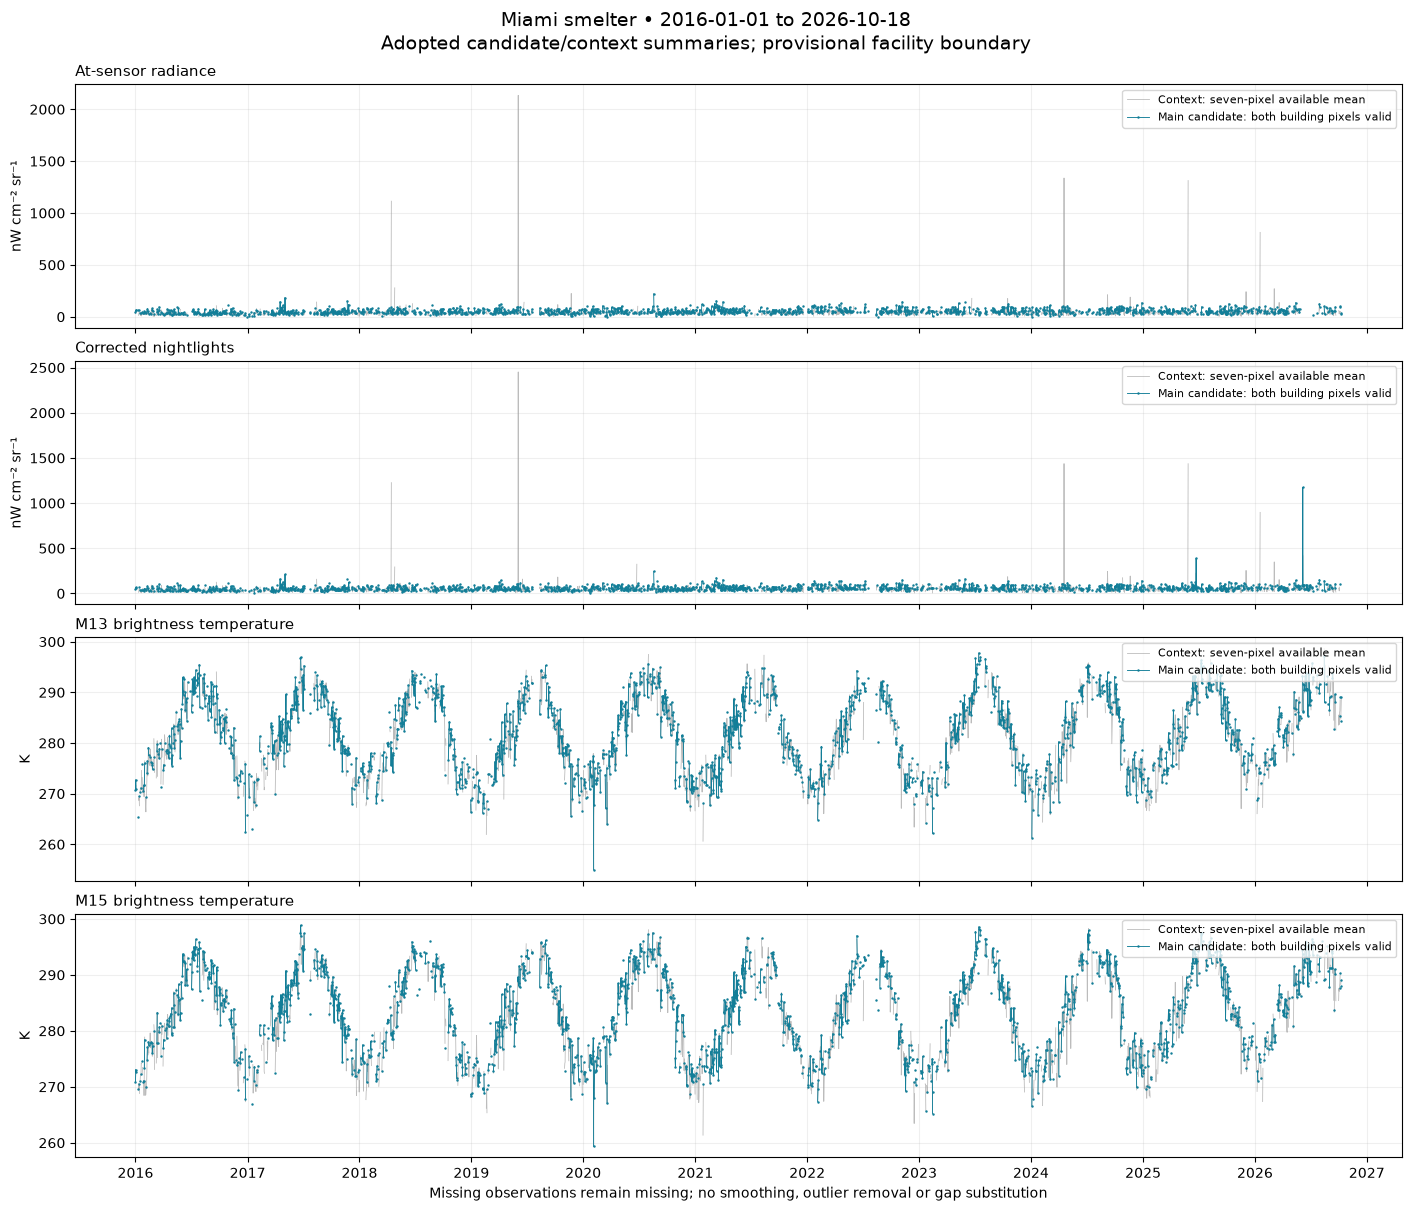

In [3]:
from nightlights.history import plot_history, open_processed_history
history_figure, history_coverage_figure, history_gap_figure = plot_history(history_daily, history_coverage, history_reference)
history_figure

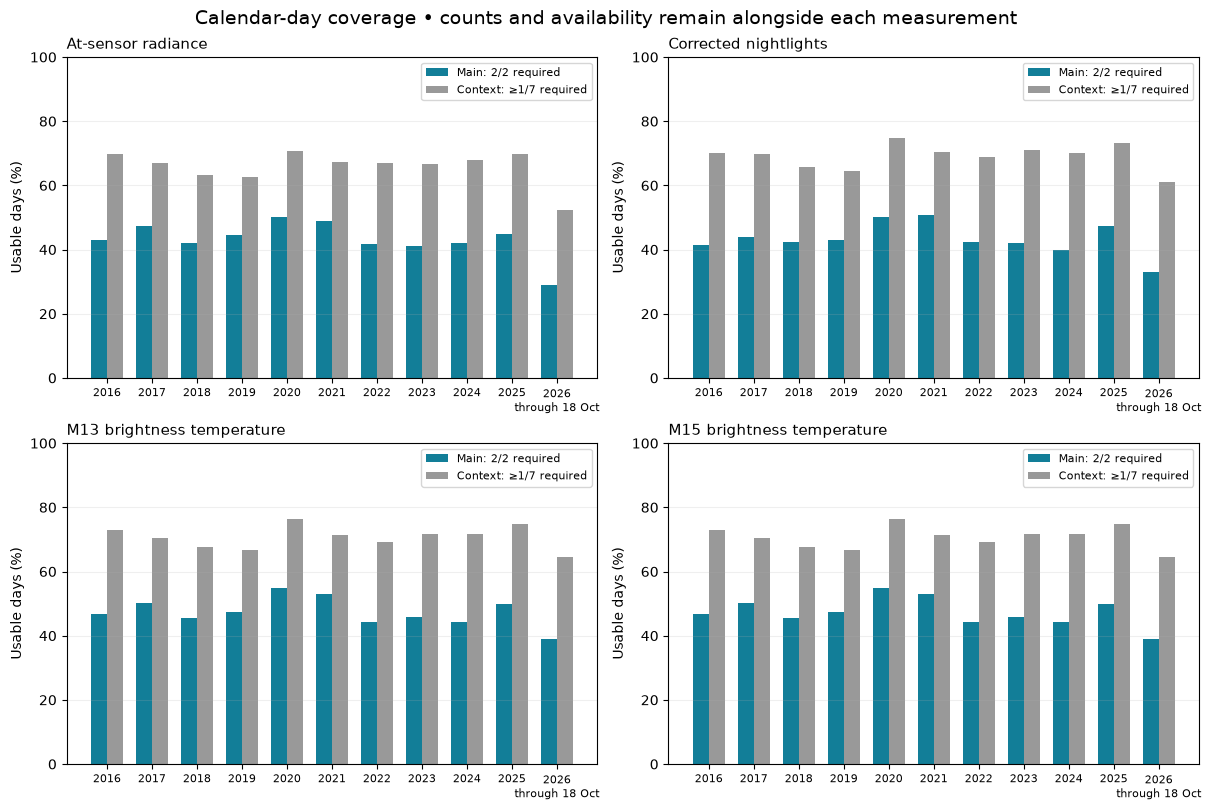

In [4]:
history_coverage_figure

### Counts stay alongside values

`main_valid_pixels` can be 0, 1 or 2; `main_value` is present only at 2.
`context_valid_pixels` ranges from 0 to 7. This prevents a one-pixel value
silently appearing as a complete main observation. Each science band is
screened separately. Values below are current observations, not gap-filled data.

In [5]:
history_daily[(history_daily.band == 'DNB_BRDF-Corrected_NTL') & (history_daily.date <= '2016-01-12')][['date','main_value','main_valid_pixels','context_value','context_valid_pixels','r0c2_value','r1c2_value','source_available']]

,date,main_value,main_valid_pixels,context_value,context_valid_pixels,r0c2_value,r1c2_value,source_available
11832,2016-01-01,47.460073,2,41.063421,3,47.075615,47.844532,True
11833,2016-01-02,67.658272,2,47.914057,7,66.865578,68.450966,True
11834,2016-01-03,65.246357,2,52.272693,6,65.256065,65.236649,True
11835,2016-01-04,NaN,0,NaN,0,NaN,NaN,True
11836,2016-01-05,NaN,0,NaN,0,NaN,NaN,True
11837,2016-01-06,NaN,0,NaN,0,NaN,NaN,True
11838,2016-01-07,NaN,0,NaN,0,NaN,NaN,True
11839,2016-01-08,NaN,0,NaN,0,NaN,NaN,True
11840,2016-01-09,NaN,0,NaN,0,NaN,NaN,True
11841,2016-01-10,NaN,0,NaN,0,NaN,NaN,True


### Gap-filled A2 reference: coverage is not freshness

VNP46A2 is a **Level-3** product. NASA's gap-filled layer uses temporal
filling, with a climatology fallback described in the user guide. It is not
necessarily a new observation for each date. Retrieval ages are retained for
each candidate pixel; 255 is missing. This reference never replaces the main
current series. A repeated value is not evidence of unchanged operations.

[NASA product](https://ladsweb.modaps.eosdis.nasa.gov/missions-and-measurements/products/VNP46A2)
· [Collection 2 guide](https://viirsland.gsfc.nasa.gov/PDF/BlackMarbleUserGuide_Collection2.0.pdf)

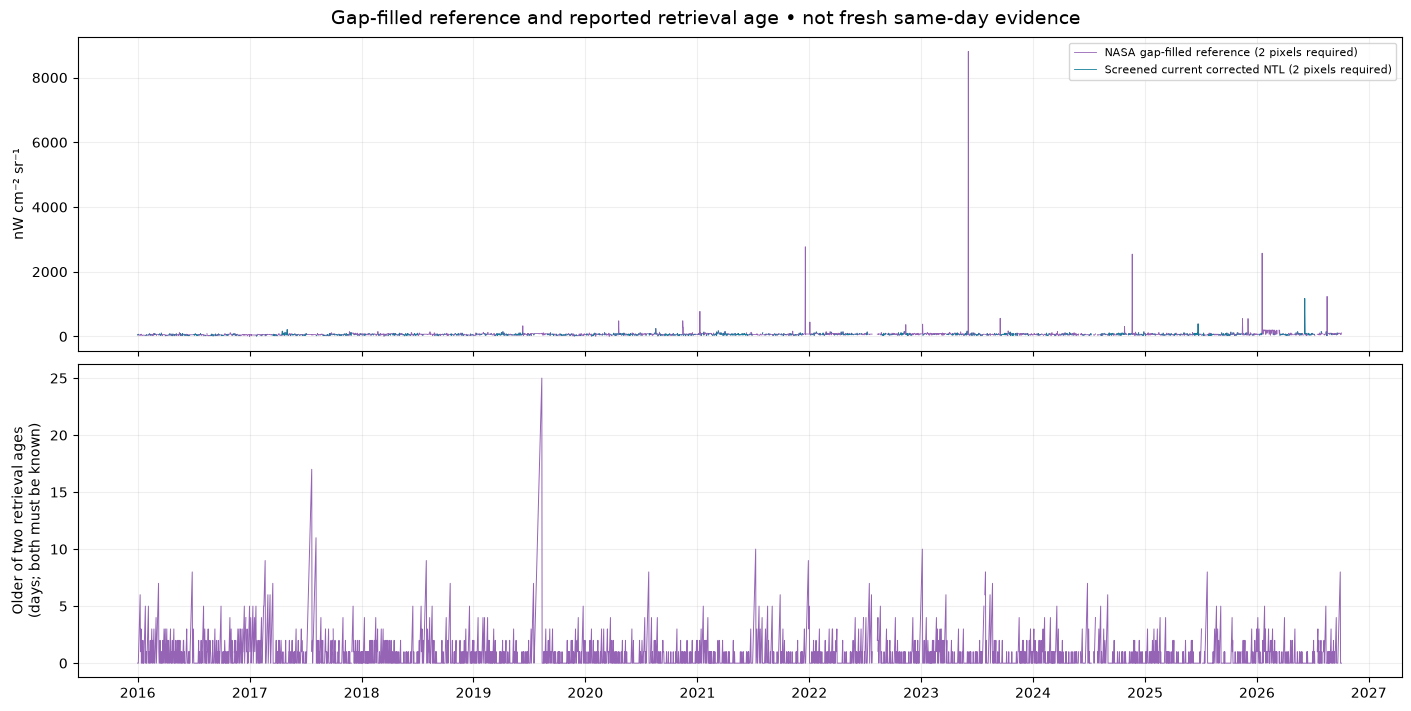

In [6]:
history_gap_figure

In [7]:
history_reference.tail(12)

,date,main_reference_value,main_reference_valid_pixels,context_reference_value,context_reference_valid_pixels,r0c2_retrieval_age_days,r1c2_retrieval_age_days,main_reference_pixels_with_known_age,main_reference_pixels_with_age_zero,main_reference_max_age_days,source_available
3932,2026-10-07,NaN,0,NaN,0,NaN,NaN,0,0,NaN,False
3933,2026-10-08,NaN,0,NaN,0,NaN,NaN,0,0,NaN,False
3934,2026-10-09,NaN,0,NaN,0,NaN,NaN,0,0,NaN,False
3935,2026-10-10,NaN,0,NaN,0,NaN,NaN,0,0,NaN,False
3936,2026-10-11,NaN,0,NaN,0,NaN,NaN,0,0,NaN,False
3937,2026-10-12,NaN,0,NaN,0,NaN,NaN,0,0,NaN,False
3938,2026-10-13,NaN,0,NaN,0,NaN,NaN,0,0,NaN,False
3939,2026-10-14,NaN,0,NaN,0,NaN,NaN,0,0,NaN,False
3940,2026-10-15,NaN,0,NaN,0,NaN,NaN,0,0,NaN,False
3941,2026-10-16,NaN,0,NaN,0,NaN,NaN,0,0,NaN,False


### xarray access without duplicating the spatial archives

`site_timeseries.zarr` stores the adopted scalar series and counts. The annual
Zarr stores retain the decoded and screened `(time,y,x)` arrays, native QA and
source provenance. The helper below joins those stores lazily into one time-sorted
spatial Dataset; no second copy of all spatial arrays is written.

In [8]:
site_series = xr.open_zarr(HISTORY/'site_timeseries.zarr', consolidated=True, chunks=None, mask_and_scale=False)
print(site_series[['DNB_BRDF-Corrected_NTL__main','DNB_BRDF-Corrected_NTL__main_valid_pixels','DNB_BRDF-Corrected_NTL__context','DNB_BRDF-Corrected_NTL__context_valid_pixels']])
site_series.close()
spatial_history = open_processed_history('VNP46A2', history_report['start'], history_report['end'])
print('Lazy spatial history:', dict(spatial_history.sizes))
spatial_history.close()

<xarray.Dataset> Size: 71kB
Dimensions:                                       (time: 3944)
Dimensions without coordinates: time
Data variables:
    DNB_BRDF-Corrected_NTL__main                  (time) float64 32kB ...
    DNB_BRDF-Corrected_NTL__main_valid_pixels     (time) uint8 4kB ...
    DNB_BRDF-Corrected_NTL__context               (time) float64 32kB ...
    DNB_BRDF-Corrected_NTL__context_valid_pixels  (time) uint8 4kB ...
Attributes:
    primary_pixels:   ["r0c2", "r1c2"]
    main_rule:        Equal mean only when both pixels pass existing quality ...
    context_rule:     Mean of available screened pixels within the seven-pixe...
    gap_filled_rule:  Separate NASA reference; never substitute for a missing...
    boundary_status:  Provisional; candidate series, not an operator-confirme...
    collection:       002
Lazy spatial history: {'y': 2, 'x': 4, 'time': 3944}


The following sections retain the original 2016 validation, boundary review
and selection-sensitivity diagnostics for traceability. The main/context choice
above is now adopted for exploration; no operational classification is implied.

## 0. Site boundary and pixel review

Yellow is the saved provisional industrial AOI; magenta is the OSM named smelter
building. Cyan outlines the nominal VIIRS cells that overlap that building.
The green star is the saved EPA facility reference point. Rows/columns use the
same zero-based identifiers as the science arrays.

The basemap is **USDA NAIP 2017 served by AZGEO**, not a 2016 image. It supports
a visual location review, not verification of historical ownership or legal limits.
The building outline is not the entire smelter operation or a furnace footprint.
FCX describes Miami as a mine, smelter and rod-mill complex; nearby industrial
structures must not automatically be attributed to the smelter building.

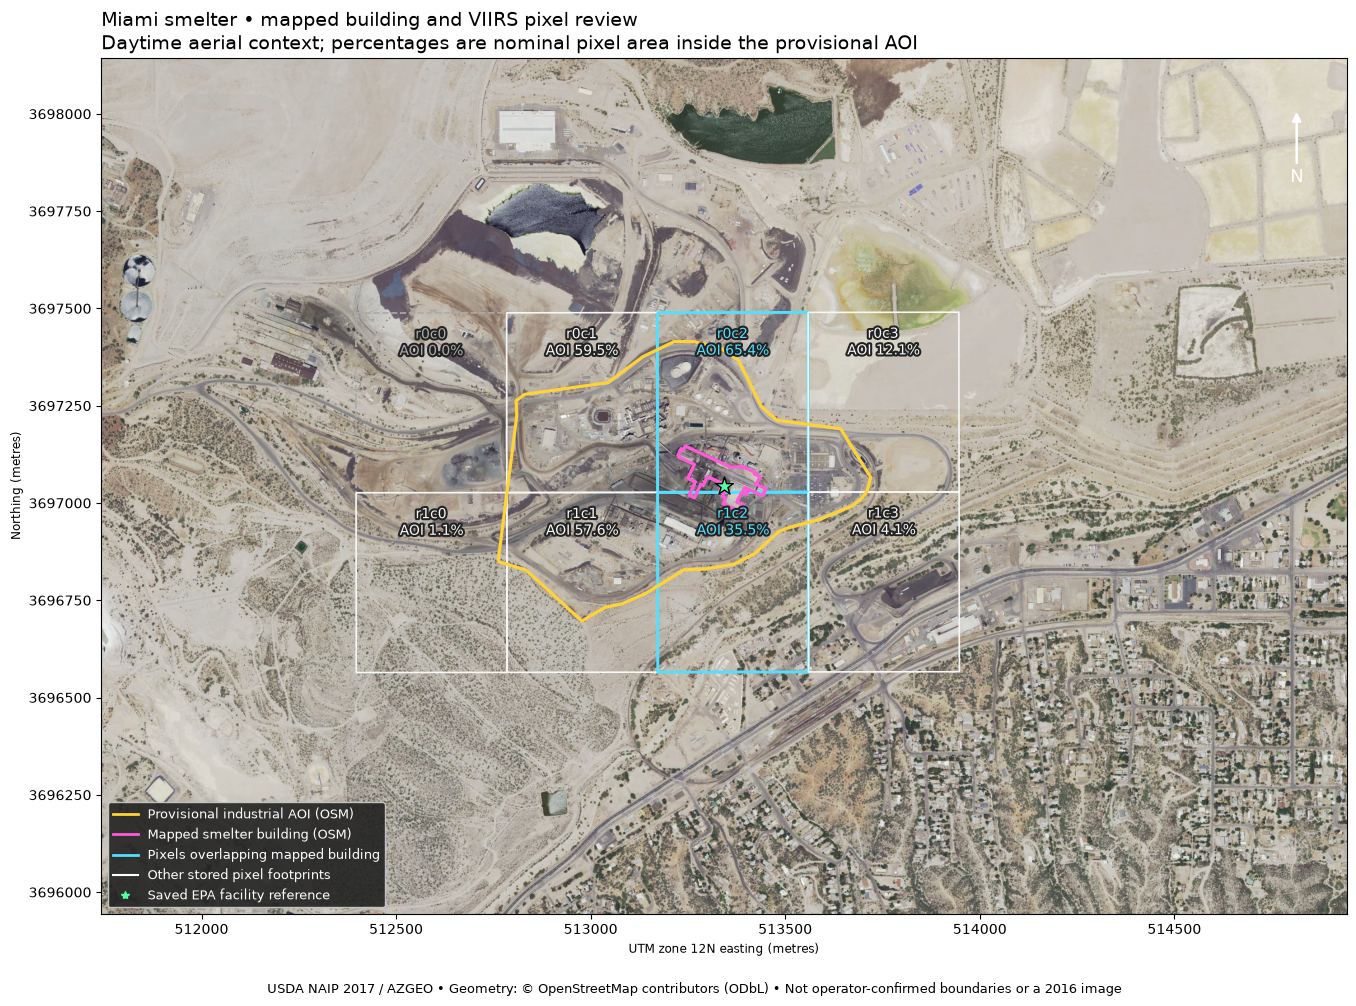

In [9]:
from nightlights.spatial import pixel_geometry, fetch_aerial, plot_site
site_report = json.loads(Path('outputs/site_review/site_review.json').read_text())
cells, site_boundary, smelter_building, site_point = pixel_geometry()
aerial_image, aerial_metadata = fetch_aerial()  # cached local image; no network
site_figure = plot_site(cells, site_boundary, smelter_building, site_point, aerial_image, aerial_metadata)
site_figure

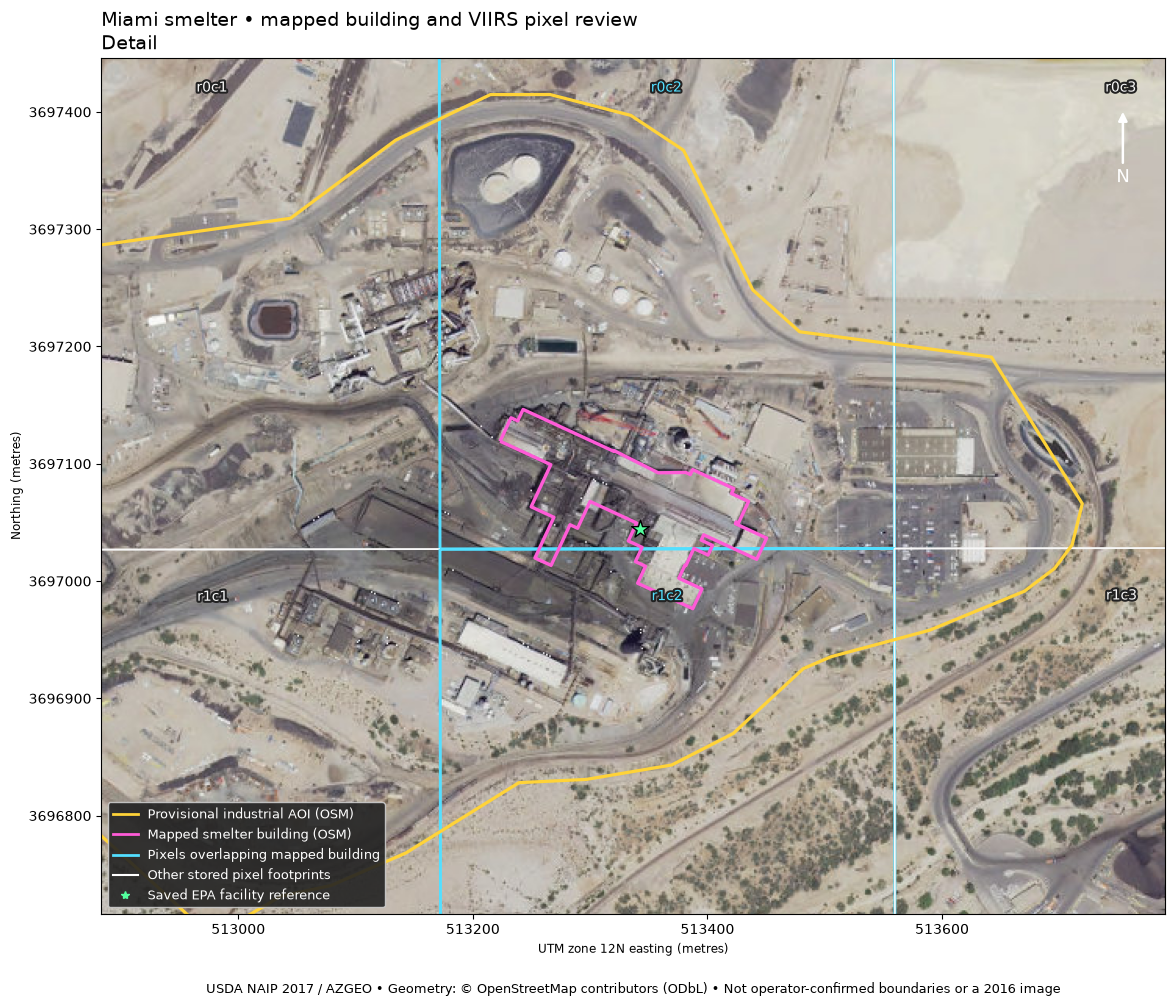

In [10]:
site_detail = plot_site(cells, site_boundary, smelter_building, site_point, aerial_image, aerial_metadata, detail=True)
site_detail

**Interpretation:** seven cells intersect the industrial AOI, but only `r0c2` and
`r1c2` overlap the mapped building. Approximately 85.8% of the building is in `r0c2`
and 14.2% in `r1c2`. That does **not** mean those pixels are pure building signal:
the mapped building occupies only about 6.9% and 1.2% of their nominal pixel areas.

Other cells include associated plant areas, yards, roads and open land. About 66.4%
of the combined area of the seven intersecting cells lies outside the provisional
AOI. These are geometric fractions, **not fractions of light contamination**.
Daytime imagery cannot establish which features emit light at night; VIIRS spatial
response, spillover and geolocation uncertainty are not modelled here.

The current AOI, raw stores and existing annual results are unchanged. Treat the
two building-overlap cells as candidates for later comparison, not a confirmed
replacement mask. Operator confirmation of the intended facility footprint remains
necessary before claiming a smelter-specific time series.

In [11]:
overlap = pd.read_csv('outputs/site_review/pixel_overlap.csv')
overlap[['pixel_id','pixel_inside_aoi_pct','building_inside_pixel_pct','pixel_covered_by_building_pct','contains_reference_point','review_role']].round(2)

,pixel_id,pixel_inside_aoi_pct,building_inside_pixel_pct,pixel_covered_by_building_pct,contains_reference_point,review_role
0,r0c0,0.00,0.00,0.00,False,outside_current_aoi
1,r0c1,59.48,0.00,0.00,False,industrial_polygon_only
2,r0c2,65.45,85.76,6.93,True,mapped_building_overlap
3,r0c3,12.06,0.00,0.00,False,industrial_polygon_only
4,r1c0,1.15,0.00,0.00,False,industrial_polygon_only
5,r1c1,57.56,0.00,0.00,False,industrial_polygon_only
6,r1c2,35.54,14.24,1.15,False,mapped_building_overlap
7,r1c3,4.08,0.00,0.00,False,industrial_polygon_only


In [12]:
overlap[['pixel_id','visual_context_2017']]

,pixel_id,visual_context_2017
0,r0c0,Outside current AOI; cleared ground and transp...
1,r0c1,Western processing/support area with structure...
2,r0c2,"Most of the mapped smelter building, plus othe..."
3,r0c3,Eastern perimeter with open ground/ponds and p...
4,r1c0,Mostly open ground and roads; only a small AOI...
5,r1c1,"Southwestern industrial yards, access routes a..."
6,r1c2,Southern part of the mapped building plus anci...
7,r1c3,"Southeastern perimeter, road corridor, parking..."


Review sources: [NAIP 2017 / AZGEO](https://azgeo.az.gov/arcgis/rest/services/imagery/NAIP2017/MapServer),
[industrial AOI](https://www.openstreetmap.org/way/675239150),
[mapped building](https://www.openstreetmap.org/way/319977306),
[FCX operations](https://fcx.com/operations/united-states).
Pixel areas are measured in UTM zone 12N (EPSG:32612); the raw science grid remains EPSG:4326.

## 1. Raw data and derived data

Each product keeps its own xarray Dataset, with time, latitude (y) and longitude (x).
The raw stores retain every calendar date and source availability. The derived stores
add physical values, screened/reference values, reason bitmasks, decoded cloud fields,
native supplemental QA and source provenance. Read with `mask_and_scale=False` so flags
and native supplemental fields retain their stored values.

In [13]:
structures = []
for product in ['VNP46A1','VNP46A2']:
    with open_product(Path('data/miami_zarr')/(product+'.zarr')) as raw:
        sample = raw.sel(time=slice(f'{YEAR}-01-01', f'{YEAR}-12-31'))
        structures.append({'product':product,'calendar_days':sample.sizes['time'],'acquired_source_days':int(sample.source_available.sum()),'pixel_rows':sample.sizes['y'],'pixel_columns':sample.sizes['x'],'AOI_pixels':int(sample.aoi_intersects_pixel.sum()),'CRS':str(sample.rio.crs)})
pd.DataFrame(structures)

,product,calendar_days,acquired_source_days,pixel_rows,pixel_columns,AOI_pixels,CRS
0,VNP46A1,366,366,2,4,7,EPSG:4326
1,VNP46A2,366,363,2,4,7,EPSG:4326


In [14]:
a1 = xr.open_zarr(OUTPUT/'VNP46A1.zarr', consolidated=True, chunks=None, mask_and_scale=False, decode_coords='all')
a2 = xr.open_zarr(OUTPUT/'VNP46A2.zarr', consolidated=True, chunks=None, mask_and_scale=False, decode_coords='all')
xr.align(a1.source_available, a2.source_available, join='exact')
a2

<xarray.Dataset> Size: 194kB
Dimensions:                                          (y: 2, x: 4, time: 366)
Coordinates:
  * y                                                (y) float64 16B 33.41 33.41
  * x                                                (x) float64 32B -110.9 ....
  * time                                             (time) datetime64[ns] 3kB ...
    spatial_ref                                      int64 8B ...
Data variables: (12/24)
    aoi_intersects_pixel                             (y, x) uint8 8B ...
    cloud_aurora                                     (time, y, x) int16 6kB ...
    cloud_cirrus                                     (time, y, x) int16 6kB ...
    cloud_cloud_confidence                           (time, y, x) int16 6kB ...
    cloud_cloud_quality                              (time, y, x) int16 6kB ...
    cloud_day                                        (time, y, x) int16 6kB ...
    ...                                               ...
    native_Mandatory_Quality_Flag                    (time, y, x) uint8 3kB ...
    native_Snow_Flag                                 (time, y, x) uint8 3kB ...
    scene_band_metadata                              (time) StringDType() 6kB ...
    source_available                                 (time) uint8 366B ...
    source_file                                      (time) StringDType() 6kB ...
    source_url                                       (time) StringDType() 6kB ...
Attributes:
    product:          VNP46A2
    processing:       Per-scene conservative quality policy v1; monthly annua...
    reason_legend:    {"1": "source_unavailable", "2": "fill_or_nonfinite", "...
    boundary_sha256:  988866215996b13fef0b2522b6a3995636ee396adfe043eff64c3a8...
    validation_year:  2016

## 2. Decode with each date's metadata

Fill values and valid ranges are tested before `physical = raw × scale_factor + offset`.
These Collection 2 radiance fields are already floating-point physical radiances;
do not apply the Collection 1 factor of 0.1. Thermal bands are brightness temperatures
in kelvin, not furnace or smelter surface temperatures. This table checks whether the
stored packing parameters change across the year; the complete per-date table is saved.

In [15]:
packing.groupby(['product','band','raw_dtype','units'], dropna=False).agg(days=('date','count'),minimum_scale=('scale','min'),maximum_scale=('scale','max'),minimum_offset=('offset','min'),maximum_offset=('offset','max')).reset_index()

,product,band,raw_dtype,units,days,minimum_scale,maximum_scale,minimum_offset,maximum_offset
0,VNP46A1,BrightnessTemperature_M13,uint16,Kelvins,366,0.0025,0.0025,203.0,203.0
1,VNP46A1,BrightnessTemperature_M15,uint16,Kelvins,366,0.0041,0.0041,111.0,111.0
2,VNP46A1,DNB_At_Sensor_Radiance,float32,nW/(cm2 sr),366,1.0000,1.0000,0.0,0.0
3,VNP46A2,DNB_BRDF-Corrected_NTL,float32,nWatts/(cm^2 sr),366,1.0000,1.0000,0.0,0.0
4,VNP46A2,Gap_Filled_DNB_BRDF-Corrected_NTL,float32,nWatts/(cm^2 sr),366,1.0000,1.0000,0.0,0.0


## 3. Monthly quality and coverage

Current values require: night, confident clear, medium/high cloud-mask quality,
no shadow/cirrus/snow/aurora/eclipse, and the relevant native band-quality flag zero.
A2 also needs a valid snow-free snow flag. Missing QA fails the screen. A1 and A2
cloud fields are decoded separately. Collection 2 A2 mandatory flag 0 is high quality;
flag 1 is not treated as a high-quality transient-light observation as in Collection 1.

These are proposed conservative analysis choices, not a universal NASA recommendation.
Coverage is retained pixel-days / possible AOI pixel-days. A day with at least one
retained pixel is not equivalent to a fully covered day. No missing data are interpolated.

In [16]:
coverage[coverage.band.isin(['DNB_At_Sensor_Radiance','DNB_BRDF-Corrected_NTL'])][['product','month','calendar_days','source_days','days_with_retained_pixels','fully_covered_days','pixel_coverage_fraction']].reset_index(drop=True)

,product,month,calendar_days,source_days,days_with_retained_pixels,fully_covered_days,pixel_coverage_fraction
0,VNP46A1,2016-01,31,31,21,5,0.456221
1,VNP46A1,2016-02,29,29,26,4,0.591133
2,VNP46A1,2016-03,31,31,22,3,0.433180
3,VNP46A1,2016-04,30,30,25,11,0.623810
4,VNP46A1,2016-05,31,31,24,7,0.580645
5,VNP46A1,2016-06,30,30,8,4,0.190476
6,VNP46A1,2016-07,31,31,19,18,0.585253
7,VNP46A1,2016-08,31,31,21,10,0.516129
8,VNP46A1,2016-09,30,30,21,14,0.623810
9,VNP46A1,2016-10,31,31,27,9,0.663594


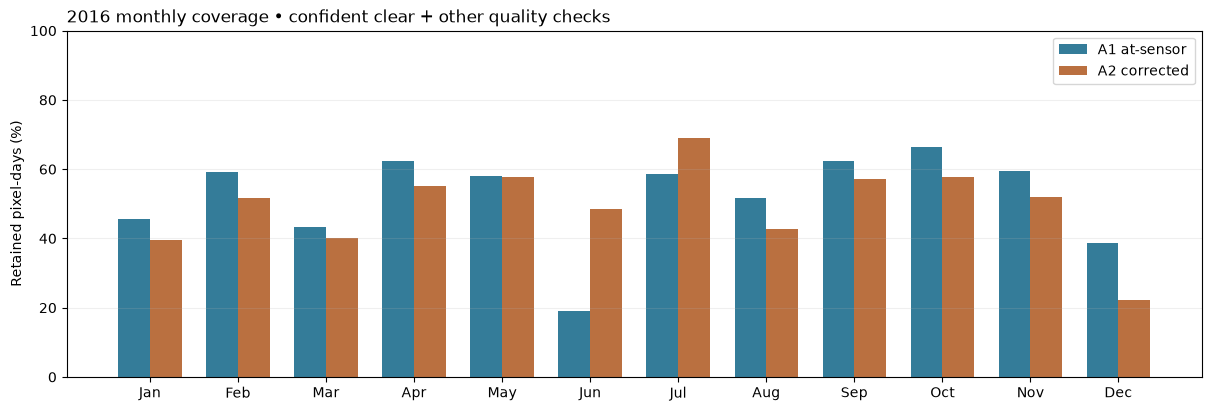

In [17]:
year_figure, coverage_figure = plot_year(daily, coverage, YEAR)
coverage_figure

## 4. Annual decoded versus screened values

The grey line is the unfiltered decoded mean where native values exist. The coloured
current series uses only pixels passing the screen. Missing days stay missing.
A changing set of retained pixels can itself alter a spatial mean. The gap-filled series
is a separate reference and never substitutes for a missing current measurement.
These plots do not establish that a change was caused by smelter operations.
A1 at-sensor radiance still includes illumination and atmospheric effects;
A2 corrected nightlights have different processing despite sharing radiance units.

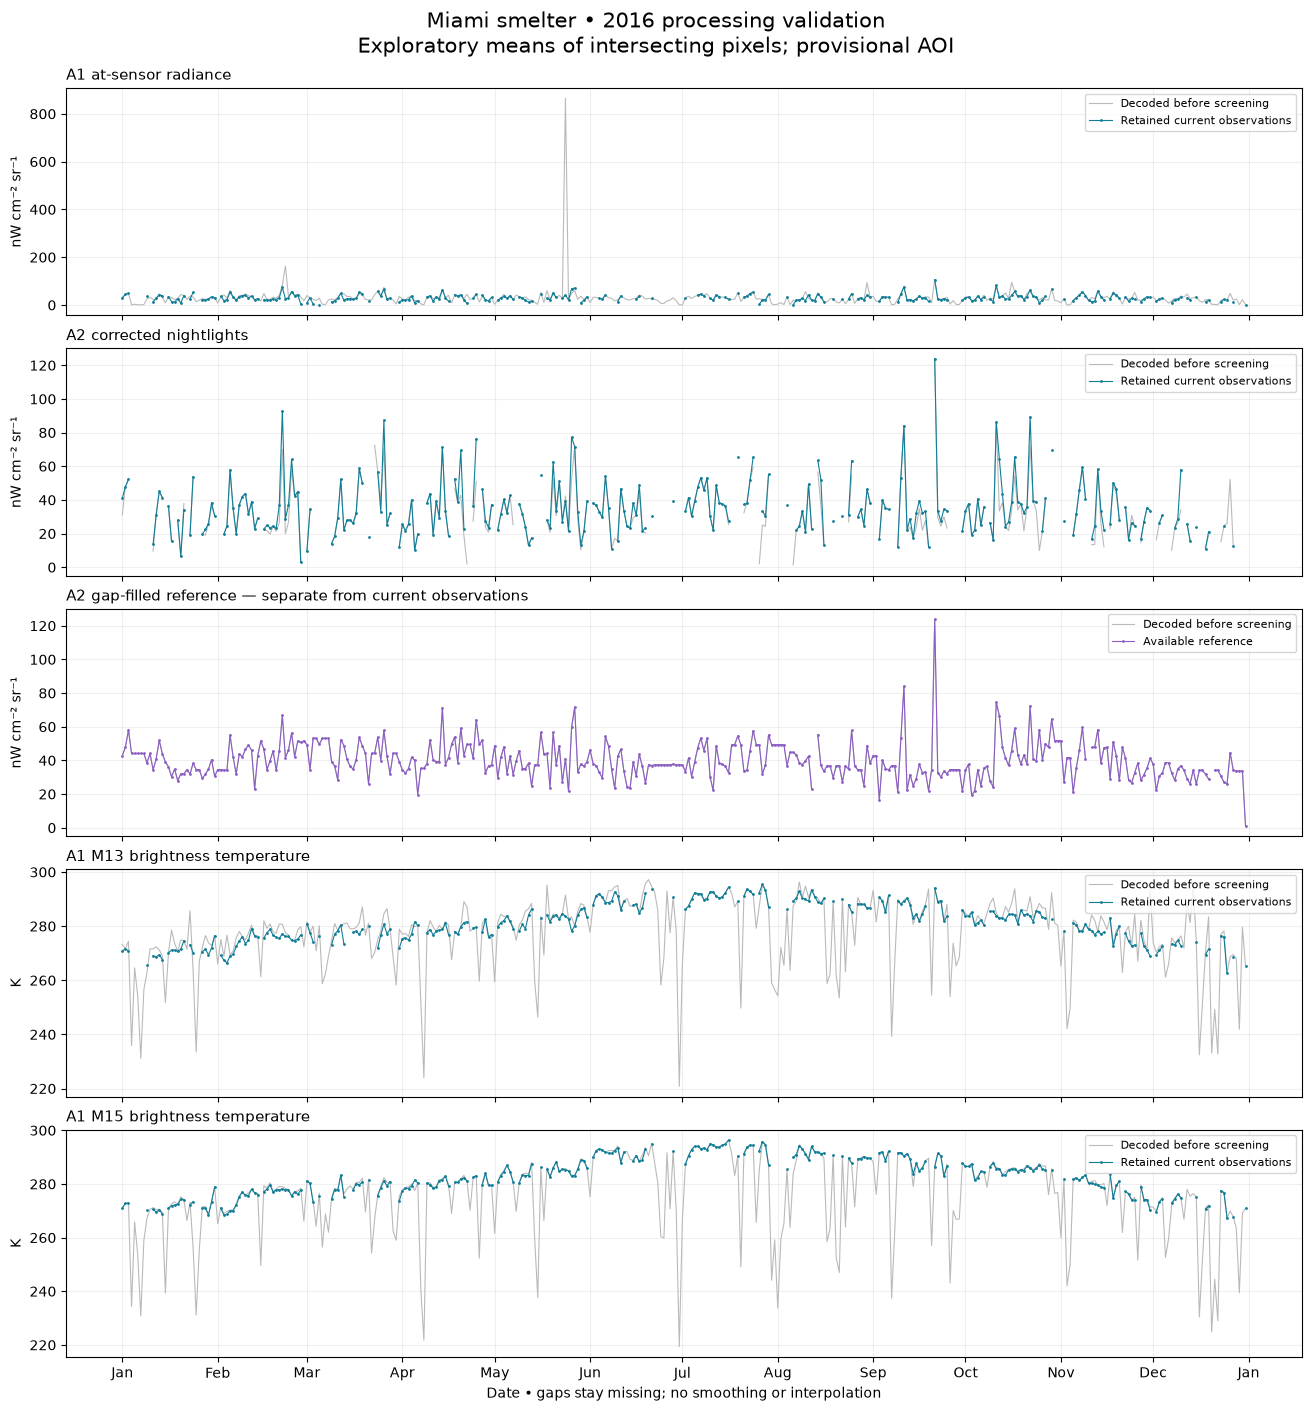

In [18]:
year_figure

## 5. Exclusions and differences between pixels

Counts below are pixel-date exclusions for each science band. Reasons can overlap,
so their sum is not a count of unique exclusions. `pixel_audit.csv` records every raw,
decoded and screened value and its reason flags. Pixel coverage matters because a
seven-pixel intersecting window includes mixed land cover and nearby lighting.

In [19]:
exclusions[exclusions.pixel_dates > 0].reset_index(drop=True)

,product,band,reason,pixel_dates
0,VNP46A1,BrightnessTemperature_M13,not_confident_clear,1093
1,VNP46A1,BrightnessTemperature_M13,cirrus,406
2,VNP46A1,BrightnessTemperature_M13,snow_ice,27
3,VNP46A1,BrightnessTemperature_M13,lunar_eclipse,3
4,VNP46A1,BrightnessTemperature_M13,band_quality_flag_not_zero,58
5,VNP46A1,BrightnessTemperature_M15,not_confident_clear,1093
6,VNP46A1,BrightnessTemperature_M15,cirrus,406
7,VNP46A1,BrightnessTemperature_M15,snow_ice,27
8,VNP46A1,BrightnessTemperature_M15,lunar_eclipse,3
9,VNP46A1,BrightnessTemperature_M15,band_quality_flag_not_zero,56


In [20]:
pixels

,product,band,row,column,longitude,latitude,retained_current_days,available_reference_days,decoded_days,mean_screened
0,VNP46A1,BrightnessTemperature_M13,0,1,-110.860417,33.414583,120,0,366,284.502790
1,VNP46A1,BrightnessTemperature_M13,0,2,-110.856250,33.414583,174,0,366,282.577455
2,VNP46A1,BrightnessTemperature_M13,0,3,-110.852083,33.414583,232,0,366,280.872886
3,VNP46A1,BrightnessTemperature_M13,1,0,-110.864583,33.410417,227,0,366,281.684359
4,VNP46A1,BrightnessTemperature_M13,1,1,-110.860417,33.410417,202,0,366,282.189924
5,VNP46A1,BrightnessTemperature_M13,1,2,-110.856250,33.410417,216,0,366,281.785183
6,VNP46A1,BrightnessTemperature_M13,1,3,-110.852083,33.410417,250,0,366,280.787308
7,VNP46A1,BrightnessTemperature_M15,0,1,-110.860417,33.414583,120,0,366,286.126957
8,VNP46A1,BrightnessTemperature_M15,0,2,-110.856250,33.414583,174,0,366,284.365249
9,VNP46A1,BrightnessTemperature_M15,0,3,-110.852083,33.414583,232,0,366,282.865939


## 6. Gap-filled reference and retrieval age

NASA's latest-high-quality-retrieval age is retained separately. It provides freshness
information; this notebook does not infer an exact acquisition timestamp. A reference
value with age greater than zero must not be interpreted as a fresh same-day measurement.
The summary below uses only available reference values inside the AOI and valid ages.

In [21]:
reference = a2[GAP+'__reference'].values
native_age = a2.native_Latest_High_Quality_Retrieval.values
valid = np.isfinite(reference) & (native_age != 255)
age = np.where(valid, native_age, np.nan)
age_rows = []
for month in range(1,13):
    rows = a2.time.dt.month.values == month
    values = age[rows]
    known = values[np.isfinite(values)]
    age_rows.append({'month':month,'reference_pixel_days_with_known_age':len(known),'age_zero_pixel_days':int((known==0).sum()),'age_above_zero_pixel_days':int((known>0).sum()),'median_age_days':float(np.median(known)) if len(known) else np.nan,'maximum_age_days':float(np.max(known)) if len(known) else np.nan})
pd.DataFrame(age_rows)

,month,reference_pixel_days_with_known_age,age_zero_pixel_days,age_above_zero_pixel_days,median_age_days,maximum_age_days
0,1,217,87,130,1.0,9.0
1,2,203,105,98,0.0,11.0
2,3,217,87,130,1.0,15.0
3,4,210,116,94,0.0,8.0
4,5,217,125,92,0.0,12.0
5,6,210,102,108,1.0,10.0
6,7,217,150,67,0.0,3.0
7,8,210,93,117,1.0,7.0
8,9,210,120,90,0.0,5.0
9,10,217,125,92,0.0,7.0


## 7. Inspect any small date window

This six-day slice retains the familiar inspection view. Change the dates to inspect
another part of the year. For a full per-pixel explanation, filter the audit CSV.

In [22]:
window = daily[(daily.date >= f'{YEAR}-01-01') & (daily.date <= f'{YEAR}-01-06')]
window[['product','date','band','decoded_pixels','retained_pixels','coverage_fraction','decoded_mean','screened_mean','reference_mean']].reset_index(drop=True)

,product,date,band,decoded_pixels,retained_pixels,coverage_fraction,decoded_mean,screened_mean,reference_mean
0,VNP46A1,2016-01-01,BrightnessTemperature_M13,7,4,0.571429,273.234284,270.762498,NaN
1,VNP46A1,2016-01-01,BrightnessTemperature_M15,7,4,0.571429,271.290672,270.928701,NaN
2,VNP46A1,2016-01-01,DNB_At_Sensor_Radiance,7,4,0.571429,31.382298,29.891710,NaN
3,VNP46A1,2016-01-02,BrightnessTemperature_M13,7,7,1.000000,271.693570,271.693570,NaN
4,VNP46A1,2016-01-02,BrightnessTemperature_M15,7,7,1.000000,272.736215,272.736215,NaN
5,VNP46A1,2016-01-02,DNB_At_Sensor_Radiance,7,7,1.000000,44.644296,44.644296,NaN
6,VNP46A1,2016-01-03,BrightnessTemperature_M13,7,6,0.857143,274.382141,270.859998,NaN
7,VNP46A1,2016-01-03,BrightnessTemperature_M15,7,6,0.857143,272.892015,272.772334,NaN
8,VNP46A1,2016-01-03,DNB_At_Sensor_Radiance,7,6,0.857143,48.388415,48.835722,NaN
9,VNP46A1,2016-01-04,BrightnessTemperature_M13,7,0,0.000000,235.922499,NaN,NaN


In [23]:
a1.close()
a2.close()
plt.close('all')
print('Results:', OUTPUT.resolve())

Results: C:\Users\zayed\OneDrive\Desktop\Earth-i\EI-Nightlights\outputs\validation_2016


## 8. Compare building-overlap pixels with the seven-pixel summary

We compare `r0c2` and `r1c2` individually, their **equal-weight mean when both
pixels are valid**, and the existing mean of available pixels in the seven-pixel
AOI. Diagnostic alternatives allow either building pixel or require all seven
AOI pixels. A mean of one surviving pixel is not treated as a two-pixel observation.

These are alternative summaries of the same screened observations. No raw data,
quality flags, boundary or adopted analysis mask change. Building-area overlap
percentages are not used as radiance weights: geometric overlap is not light-source
attribution. Gap-filled reference values do not enter these comparisons.

In [24]:
from nightlights.comparison import plot_comparison
COMPARISON = Path('outputs/pixel_comparison_2016')
selections = pd.read_csv(COMPARISON/'daily_selections.csv')
selection_summary = pd.read_csv(COMPARISON/'selection_summary.csv')
matched_metrics = pd.read_csv(COMPARISON/'matched_date_metrics.csv')
selection_coverage = pd.read_csv(COMPARISON/'monthly_coverage.csv')
high_dates = pd.read_csv(COMPARISON/'shared_date_high_values.csv')
selection_summary.pivot(index='band',columns='selection',values='valid_days')

selection,aoi_all,aoi_any,pair_any,pair_both,r0c2,r1c2
band,,,,,,
BrightnessTemperature_M13,111,267,219,171,174,216
BrightnessTemperature_M15,111,267,219,171,174,216
DNB_At_Sensor_Radiance,98,255,210,157,163,204
DNB_BRDF-Corrected_NTL,73,256,215,152,158,209


`pair_both` is the primary combined series (2/2 valid). `pair_any` permits 1/2
and therefore changes its spatial composition. `aoi_any` reproduces the previous
summary (at least 1/7), while `aoi_all` requires a fixed 7/7 footprint. Coverage
differences are part of the result, not a reason to fill missing observations.

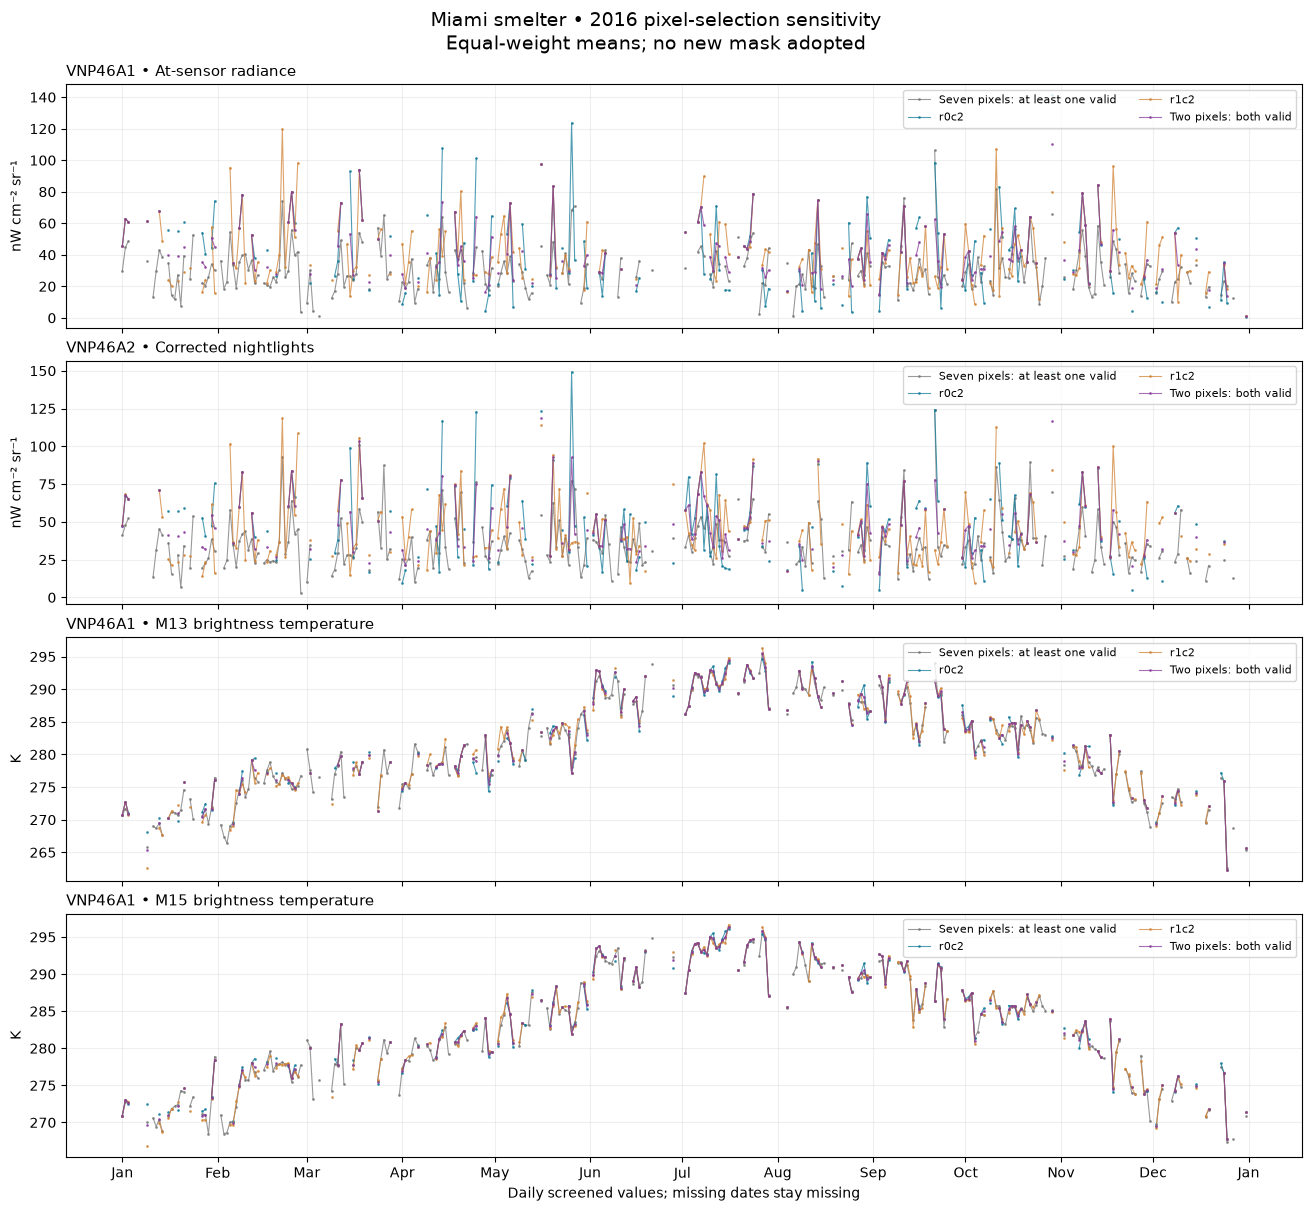

In [25]:
selection_figure, matched_figure, selection_coverage_figure = plot_comparison(selections, matched_metrics, selection_coverage, YEAR)
selection_figure

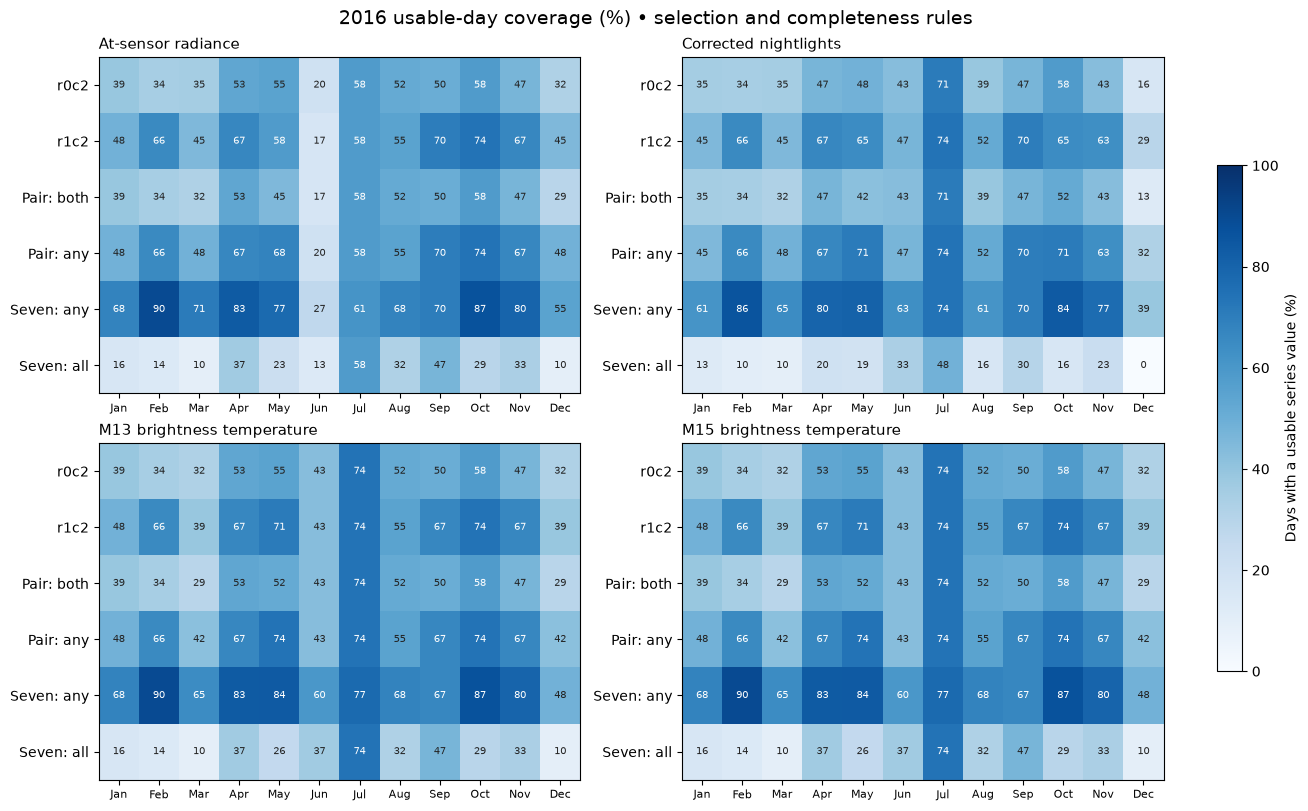

In [26]:
selection_coverage_figure

### Fair comparison on shared valid dates

Means, differences, correlations and high-value dates below use **the same dates
for each pair of series**. The seven-all comparison further holds the full AOI
footprint fixed, helping distinguish spatial differences from incomplete coverage.
Own-available-date means in the CSV are descriptive only and should not be compared
as though they sample the same dates.

Pearson and rank correlations are descriptive. These series share input pixels;
agreement is not independent validation of a smelter operational signal. Likewise,
a higher two-pixel mean does not establish that the difference is smelter-only light.

In [27]:
matched_metrics[(matched_metrics.left == 'pair_both') & matched_metrics.right.isin(['aoi_any','aoi_all'])][['product','band','right','common_days','left_mean','right_mean','mean_difference_left_minus_right','pearson_r','spearman_r']].round(3).reset_index(drop=True)

,product,band,right,common_days,left_mean,right_mean,mean_difference_left_minus_right,pearson_r,spearman_r
0,VNP46A1,DNB_At_Sensor_Radiance,aoi_any,157,41.899,33.010,8.889,0.734,0.770
1,VNP46A1,DNB_At_Sensor_Radiance,aoi_all,98,40.687,33.893,6.794,0.714,0.747
2,VNP46A2,DNB_BRDF-Corrected_NTL,aoi_any,152,47.205,38.433,8.773,0.718,0.768
3,VNP46A2,DNB_BRDF-Corrected_NTL,aoi_all,73,46.471,38.849,7.622,0.679,0.757
4,VNP46A1,BrightnessTemperature_M13,aoi_any,171,282.630,282.505,0.125,0.997,0.996
5,VNP46A1,BrightnessTemperature_M13,aoi_all,111,284.437,284.264,0.173,0.996,0.994
6,VNP46A1,BrightnessTemperature_M15,aoi_any,171,284.397,284.321,0.075,0.999,0.999
7,VNP46A1,BrightnessTemperature_M15,aoi_all,111,286.325,286.192,0.133,0.999,0.998


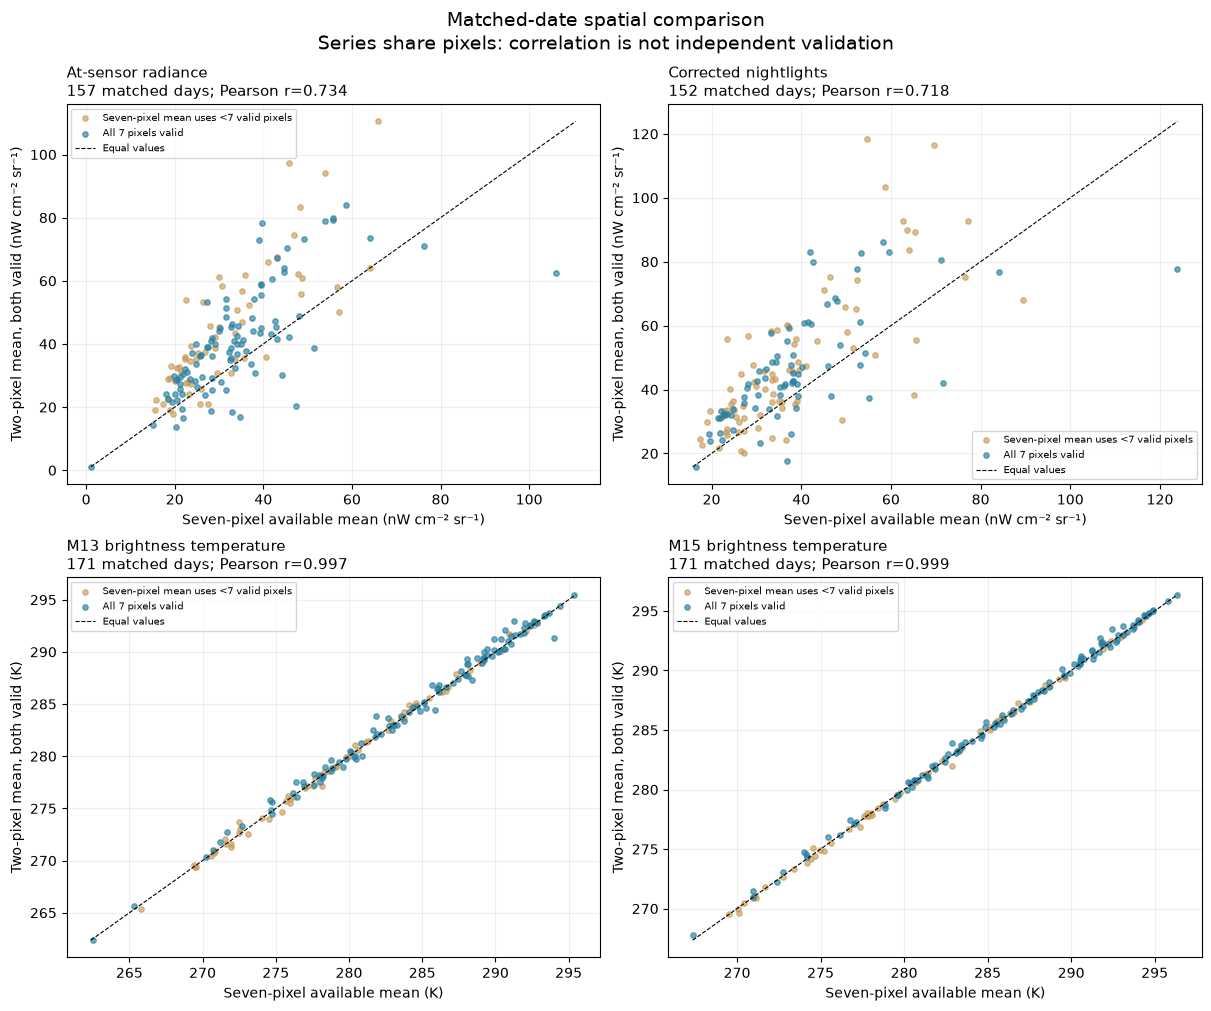

In [28]:
matched_figure

### Do high values occur on the same dates?

For this review, high-value dates are at or above each series' 90th percentile
on their shared-date subset; ties are included. These are upper-decile dates,
not detected operating events or a local-maximum detector. Maximum dates and
top-date overlaps are recorded separately. Thresholds change when the matched
subset changes, so read the common-day count with every comparison.

In [29]:
matched_metrics[(matched_metrics.left == 'pair_both') & (matched_metrics.right == 'aoi_any')][['band','common_days','left_upper_decile_days','right_upper_decile_days','shared_upper_decile_days','upper_decile_jaccard','left_maximum_date','right_maximum_date','maximum_date_sets_overlap']].round(3).reset_index(drop=True)

,band,common_days,left_upper_decile_days,right_upper_decile_days,shared_upper_decile_days,upper_decile_jaccard,left_maximum_date,right_maximum_date,maximum_date_sets_overlap
0,DNB_At_Sensor_Radiance,157,16,16,9,0.391,2016-10-29,2016-09-21,False
1,DNB_BRDF-Corrected_NTL,152,16,16,10,0.455,2016-05-16,2016-09-21,False
2,BrightnessTemperature_M13,171,18,18,16,0.800,2016-07-27,2016-07-27,True
3,BrightnessTemperature_M15,171,18,18,16,0.800,2016-07-16,2016-07-16,True


In [30]:
high_dates[(high_dates.band == 'DNB_BRDF-Corrected_NTL') & (high_dates.comparison == 'pair_both vs aoi_any')][['date','left_value','right_value','left_high','right_high','aoi_valid_pixels']].round(3).reset_index(drop=True)

,date,left_value,right_value,left_high,right_high,aoi_valid_pixels
0,2016-02-09,82.957,42.031,True,False,7
1,2016-02-25,83.671,64.077,True,True,6
2,2016-03-12,77.677,52.355,True,False,7
3,2016-03-18,103.320,58.694,True,True,4
4,2016-04-14,80.577,71.241,True,True,7
5,2016-04-25,75.084,76.440,False,True,4
6,2016-05-06,80.046,42.671,True,False,7
7,2016-05-16,118.496,54.585,True,False,6
8,2016-05-20,92.701,62.746,True,True,5
9,2016-05-26,92.684,77.273,True,True,4


**Decision still to make:** choose the spatial summary and minimum valid-pixel
rule before extending derived processing. The two-pixel series targets the mapped
building more closely geometrically, but has lower coverage and remains mixed.
Keep the seven-pixel series as context during that decision; no replacement has
been adopted automatically.

## Next scientific decisions

Review the seasonal coverage and per-pixel results, confirm the smelter AOI, and decide
whether this screen suits the intended analysis before extending derived processing
beyond 2016. No outlier clipping, smoothing, band substitution or activity classification
is performed. Annual Zarr stores are separate from the raw stores. Completed monthly
processing is reused when input and policy signatures match; altered inputs are rechecked.

**References:**

- [NASA Collection 2 A1 specification](https://ladsweb.modaps.eosdis.nasa.gov/filespec/VIIRS/2/VNP46A1_v2.0.fs)
- [NASA Collection 2 A2 specification](https://ladsweb.modaps.eosdis.nasa.gov/filespec/VIIRS/2/VNP46A2_v2.0.fs)
- [NASA Collection 2 user guide](https://viirsland.gsfc.nasa.gov/PDF/BlackMarbleUserGuide_Collection2.0.pdf)